# Weather Image Classification with FastViT (built from scratch)

Training a **FastViT** hybrid vision transformer, implemented from scratch in PyTorch (no pretrained weights), on the [Weather Image Recognition](https://www.kaggle.com/datasets/jehanbhathena/weather-dataset) dataset (11 classes).

# 1. Setup

## 1.1 Imports

In [1]:
import os
import gc
import ctypes
import copy
import math
import time
import random
import warnings
from io import BytesIO
from pathlib import Path
from collections import OrderedDict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import psutil
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    top_k_accuracy_score,
    precision_recall_fscore_support,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.flop_counter import FlopCounterMode
import torchvision.transforms as T

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print(f"torch {torch.__version__} | CUDA available: {torch.cuda.is_available()} | GPUs: {torch.cuda.device_count()}")

torch 2.11.0+cu128 | CUDA available: True | GPUs: 2


## 1.2 Configuration

In [46]:
class CFG:
    SEED = 42
    INPUT_ROOT = "/kaggle/input"
    DATA_DIR = None
    OUTPUT_DIR = "/kaggle/working"
    CHECKPOINT_NAME = "fastvit_weather_best.pth"
    IMG_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif")

    VAL_SIZE = 0.15
    TEST_SIZE = 0.15
    SAMPLES_PER_CLASS = 6

    IMG_SIZE = 224
    CACHE_MODE = "disk"
    CACHE_DIR = "/tmp/weather_cache"
    CACHE_JPEG_QUALITY = 95
    CACHE_SHORT_SIDE = 256
    IO_THREADS = 8
    NORM_STATS = "dataset"
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)
    RRC_SCALE = (0.3, 1.0)
    AUTO_AUGMENT = "trivial"
    RANDOM_ERASING = 0.25

    MODEL_VARIANT = "fastvit_sa12"
    DROP_RATE = 0.1
    DROP_PATH_RATE = 0.1
    LAYER_SCALE_INIT = 1e-5
    CLS_RATIO = 2.0

    EPOCHS = 120
    BATCH_SIZE = 128
    EVAL_BATCH_SIZE = 128
    NUM_WORKERS = min(4, os.cpu_count())
    EVAL_NUM_WORKERS = 2
    PREFETCH_FACTOR = 2
    REQUIRE_GPU = True
    LR = 1e-3
    MIN_LR = 1e-6
    WARMUP_EPOCHS = 5
    WEIGHT_DECAY = 0.05
    LABEL_SMOOTHING = 0.1
    MIXUP_ALPHA = 0.8
    CUTMIX_ALPHA = 1.0
    MIX_PROB = 0.8
    MIX_SWITCH_PROB = 0.5
    MIX_OFF_LAST_EPOCHS = 15
    USE_CLASS_WEIGHTS = True
    CLASS_WEIGHT_CLIP = 5.0
    USE_AMP = True
    GRAD_CLIP = 5.0
    USE_EMA = True
    EMA_DECAY = 0.998
    MONITOR = "val_f1"
    PATIENCE = 40
    MULTI_GPU = False
    MALLOC_THRESHOLD = 65536
    RELEASE_MEMORY_EVERY_EPOCH = True

    TTA = True
    TOP_K = 3
    N_PRED_SAMPLES = 24
    N_ERROR_SAMPLES = 12
    BENCHMARK_RUNS = 50

    URLS = [
        "https://upload.wikimedia.org/wikipedia/commons/f/f1/A_drop_of_dew_on_a_clover.jpg",
        "https://cms.accuweather.com/wp-content/uploads/2019/01/static-hoarfrost-germany-ap.jpg",
        "https://images.pexels.com/photos/35713204/pexels-photo-35713204/free-photo-of-snow-covered-trees-in-serene-winter-landscape.jpeg?cs=tinysrgb&dpr=1&w=500",
        "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQY6cbdaywisZB_EMnoEnuV76B_FQyq9jqdB8JSwDI3GQ&s=10",
        "https://upload.wikimedia.org/wikipedia/commons/9/94/Granizo.jpg",
        "https://upload.wikimedia.org/wikipedia/commons/c/c2/Port_and_lighthouse_overnight_storm_with_lightning_in_Port-la-Nouvelle.jpg",
        "https://upload.wikimedia.org/wikipedia/commons/6/65/Hard_rain_on_a_roof.jpg",
        "https://upload.wikimedia.org/wikipedia/commons/5/5c/Double-alaskan-rainbow.jpg",
        "https://upload.wikimedia.org/wikipedia/commons/8/8b/Rime_ice.jpg",
        "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQPZ5OMU_ajRzzXcfSazRbHX-yum35SsWy3-wBMmgwcKwmwTH9jv06uZzkr&s=10",
        "https://upload.wikimedia.org/wikipedia/commons/1/12/CargoNet_Di_12_Euro_4000_L%C3%B8nsdal_-_Bolna.jpg",
    ]
    URL_USER_AGENT = "Mozilla/5.0 (compatible; WeatherFastViT/1.0; educational Kaggle notebook)"


pd.DataFrame(
    [(k, v) for k, v in vars(CFG).items() if not k.startswith("_") and k != "URLS"],
    columns=["parameter", "value"],
)

,parameter,value
0,SEED,42
1,INPUT_ROOT,/kaggle/input
2,DATA_DIR,None
3,OUTPUT_DIR,/kaggle/working
4,CHECKPOINT_NAME,fastvit_weather_best.pth
5,IMG_EXTENSIONS,"(.jpg, .jpeg, .png, .bmp, .webp, .gif)"
6,VAL_SIZE,0.15
7,TEST_SIZE,0.15
8,SAMPLES_PER_CLASS,6
9,IMG_SIZE,224


## 1.3 Reproducibility & Devices

In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


seed_everything(CFG.SEED)
if CFG.REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. In Kaggle: Settings > Accelerator > GPU T4 x2, then restart the session.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()
USE_DP = CFG.MULTI_GPU and N_GPUS > 1
AMP_ENABLED = CFG.USE_AMP and DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
os.makedirs(CFG.OUTPUT_DIR, exist_ok=True)

print(f"Device: {DEVICE} | DataParallel: {USE_DP} | AMP: {AMP_ENABLED} | CPU workers: {CFG.NUM_WORKERS}")
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i} {props.name} | {props.total_memory / 1024**3:.1f} GB")


try:
    LIBC = ctypes.CDLL("libc.so.6")
    LIBC.mallopt(-1, CFG.MALLOC_THRESHOLD)
    LIBC.mallopt(-3, CFG.MALLOC_THRESHOLD)
except (OSError, AttributeError):
    LIBC = None


def ram_gb():
    main = psutil.Process()
    workers = 0
    for c in main.children(recursive=True):
        try:
            workers += c.memory_full_info().uss
        except psutil.Error:
            pass
    return main.memory_info().rss / 1024**3, workers / 1024**3


def release_memory():
    gc.collect()
    if LIBC is not None:
        LIBC.malloc_trim(0)
    if torch.cuda.is_available() and hasattr(torch._C, "_host_emptyCache"):
        torch._C._host_emptyCache()


vm = psutil.virtual_memory()
print(f"RAM: total {vm.total / 1024**3:.1f} GB | available {vm.available / 1024**3:.1f} GB | "
      f"this notebook {sum(ram_gb()):.2f} GB | glibc tuning: {LIBC is not None}")


def unwrap(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def maybe_parallel(model):
    return nn.DataParallel(model) if USE_DP else model

Device: cuda | DataParallel: False | AMP: True | CPU workers: 4
  cuda:0 Tesla T4 | 14.6 GB
  cuda:1 Tesla T4 | 14.6 GB
RAM: total 31.3 GB | available 29.5 GB | this notebook 0.82 GB | glibc tuning: True


# 2. Data Analysis

## 2.1 Dataset Index

In [48]:
def find_data_dir(root, required=("rainbow", "lightning", "sandstorm")):
    for dirpath, dirnames, _ in os.walk(root):
        if set(required).issubset({d.lower() for d in dirnames}):
            return dirpath
    raise FileNotFoundError(f"Weather dataset not found under {root}. Add 'jehanbhathena/weather-dataset' as notebook input.")


CFG.DATA_DIR = CFG.DATA_DIR or find_data_dir(CFG.INPUT_ROOT)
CFG.CLASSES = sorted(d for d in os.listdir(CFG.DATA_DIR) if os.path.isdir(os.path.join(CFG.DATA_DIR, d)))
CFG.NUM_CLASSES = len(CFG.CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CFG.CLASSES)}

records = [
    {"path": str(p), "label": c}
    for c in CFG.CLASSES
    for p in sorted(Path(CFG.DATA_DIR, c).iterdir())
    if p.suffix.lower() in CFG.IMG_EXTENSIONS
]
df = pd.DataFrame(records)
df["target"] = df["label"].map(CLASS_TO_IDX)

print(f"Data dir: {CFG.DATA_DIR}")
print(f"Images: {len(df)} | Classes ({CFG.NUM_CLASSES}): {CFG.CLASSES}")
df.head()

Data dir: /kaggle/input/datasets/jehanbhathena/weather-dataset/dataset
Images: 6862 | Classes (11): ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


,path,label,target
0,/kaggle/input/datasets/jehanbhathena/weather-d...,dew,0
1,/kaggle/input/datasets/jehanbhathena/weather-d...,dew,0
2,/kaggle/input/datasets/jehanbhathena/weather-d...,dew,0
3,/kaggle/input/datasets/jehanbhathena/weather-d...,dew,0
4,/kaggle/input/datasets/jehanbhathena/weather-d...,dew,0


## 2.2 Class Distribution

,count,percent
label,,
rime,1160,16.90
fogsmog,851,12.40
dew,698,10.17
sandstorm,692,10.08
glaze,639,9.31
snow,621,9.05
hail,591,8.61
rain,526,7.67
frost,475,6.92


Imbalance ratio (max/min): 5.00


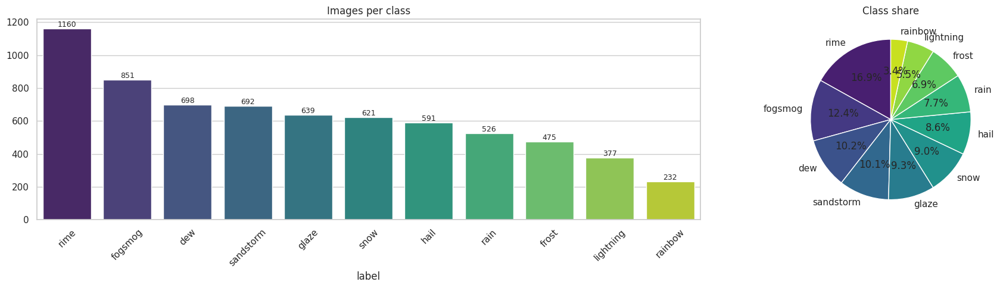

In [5]:
counts = df["label"].value_counts().reindex(CFG.CLASSES)
dist = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(2)})
display(dist.sort_values("count", ascending=False))
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [2, 1]})
order = counts.sort_values(ascending=False).index
sns.barplot(x=order, y=counts[order].values, ax=axes[0], palette="viridis")
for i, v in enumerate(counts[order].values):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
axes[0].set_title("Images per class")
axes[0].tick_params(axis="x", rotation=45)
axes[1].pie(counts[order].values, labels=order, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("viridis", len(order)))
axes[1].set_title("Class share")
plt.tight_layout()
plt.show()

## 2.3 Image Properties

In [6]:
def read_header(path):
    size_kb = os.path.getsize(path) / 1024
    try:
        with Image.open(path) as im:
            return {"width": im.width, "height": im.height, "mode": im.mode, "format": im.format, "size_kb": size_kb}
    except Exception:
        return {"width": np.nan, "height": np.nan, "mode": "unreadable", "format": "unreadable", "size_kb": size_kb}


with ThreadPoolExecutor(CFG.IO_THREADS) as ex:
    meta = list(tqdm(ex.map(read_header, df["path"]), total=len(df), desc="Reading headers"))
df = pd.concat([df, pd.DataFrame(meta)], axis=1)
df["aspect_ratio"] = df["width"] / df["height"]
df["megapixels"] = df["width"] * df["height"] / 1e6

display(df[["width", "height", "aspect_ratio", "megapixels", "size_kb"]].describe().T.round(2))
display(pd.crosstab(df["label"], df["mode"], margins=True))
display(pd.crosstab(df["label"], df["format"], margins=True))

Reading headers:   0%|          | 0/6862 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
width,6862.0,520.03,352.02,117.00,400.00,400.00,500.00,4863.00
height,6862.0,373.84,251.42,91.00,255.00,280.00,400.00,3174.00
aspect_ratio,6862.0,1.44,0.32,0.48,1.33,1.50,1.57,4.66
megapixels,6862.0,0.27,0.69,0.01,0.10,0.11,0.18,15.44
size_kb,6862.0,90.62,195.41,1.65,19.28,35.59,81.68,3504.93


mode,L,P,RGB,RGBA,All
label,,,,,
dew,5,0,691,2,698
fogsmog,36,1,796,18,851
frost,0,0,475,0,475
glaze,5,0,632,2,639
hail,16,0,564,11,591
lightning,3,0,370,4,377
rain,6,0,509,11,526
rainbow,0,0,230,2,232
rime,6,0,1150,4,1160


format,BMP,GIF,JPEG,PNG,All
label,,,,,
dew,0,0,693,5,698
fogsmog,0,1,818,32,851
frost,0,0,460,15,475
glaze,0,0,631,8,639
hail,0,0,569,22,591
lightning,0,0,369,8,377
rain,0,0,508,18,526
rainbow,0,0,227,5,232
rime,0,0,1151,9,1160


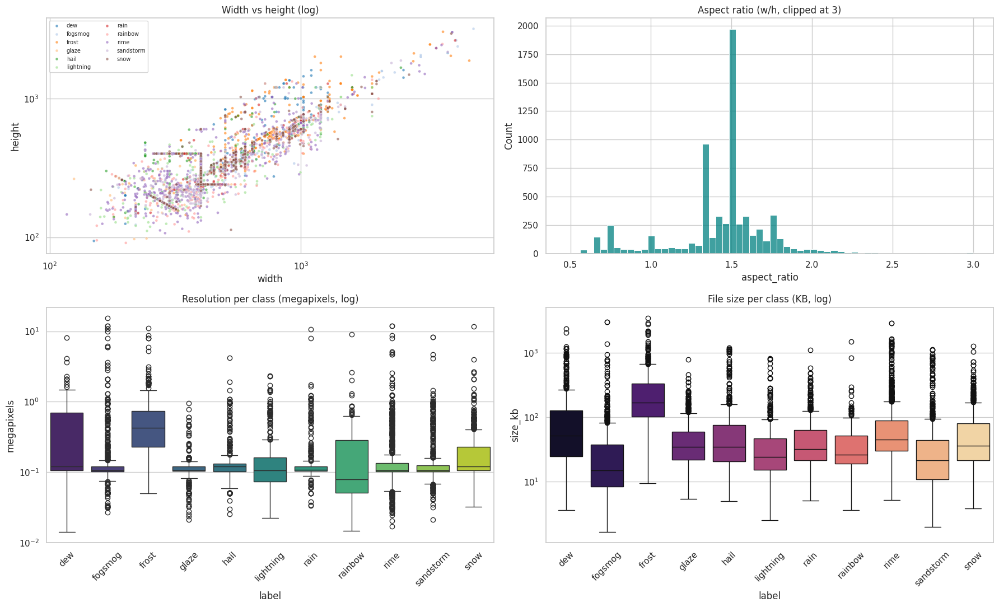

Images with short side < 224px: 838 (12.2%)


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
sns.scatterplot(data=df, x="width", y="height", hue="label", s=12, alpha=0.6, ax=axes[0, 0], palette="tab20")
axes[0, 0].set(xscale="log", yscale="log", title="Width vs height (log)")
axes[0, 0].legend(fontsize=7, ncol=2)
sns.histplot(df["aspect_ratio"].clip(0, 3), bins=60, ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Aspect ratio (w/h, clipped at 3)")
sns.boxplot(data=df, x="label", y="megapixels", ax=axes[1, 0], palette="viridis", order=CFG.CLASSES)
axes[1, 0].set(yscale="log", title="Resolution per class (megapixels, log)")
axes[1, 0].tick_params(axis="x", rotation=45)
sns.boxplot(data=df, x="label", y="size_kb", ax=axes[1, 1], palette="magma", order=CFG.CLASSES)
axes[1, 1].set(yscale="log", title="File size per class (KB, log)")
axes[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

small = (df[["width", "height"]].min(axis=1) < CFG.IMG_SIZE).sum()
print(f"Images with short side < {CFG.IMG_SIZE}px: {small} ({100 * small / len(df):.1f}%)")

## 2.4 Image Loading, Validation & Cache

In [8]:
def load_image(path, short_side=None):
    with Image.open(path) as im:
        if short_side and im.format == "JPEG":
            im.draft("RGB", (short_side, short_side))
        im = im.convert("RGB")
    if short_side:
        w, h = im.size
        scale = short_side / min(w, h)
        if scale < 1:
            im = im.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
    return im


def image_stats(im):
    rgb = np.asarray(im.resize((64, 64)), dtype=np.float32) / 255.0
    hsv = np.asarray(im.resize((64, 64)).convert("HSV"), dtype=np.float32) / 255.0
    m, sq = rgb.mean((0, 1)), (rgb**2).mean((0, 1))
    return {
        "mean_r": m[0], "mean_g": m[1], "mean_b": m[2],
        "sq_r": sq[0], "sq_g": sq[1], "sq_b": sq[2],
        "saturation": hsv[..., 1].mean(), "brightness": hsv[..., 2].mean(),
    }


def cache_path(path):
    p = Path(path)
    return os.path.join(CFG.CACHE_DIR, p.parent.name, p.name + ".jpg")


def safe_load(path):
    try:
        im = load_image(path, CFG.CACHE_SHORT_SIDE)
        stats = image_stats(im)
    except Exception:
        return None, None
    if CFG.CACHE_MODE == "disk":
        target = cache_path(path)
        im.save(target, quality=CFG.CACHE_JPEG_QUALITY)
        return target, stats
    return (im if CFG.CACHE_MODE == "ram" else path), stats


if CFG.CACHE_MODE == "disk":
    for c in CFG.CLASSES:
        os.makedirs(os.path.join(CFG.CACHE_DIR, c), exist_ok=True)

with ThreadPoolExecutor(CFG.IO_THREADS) as ex:
    loaded = list(tqdm(ex.map(safe_load, df["path"]), total=len(df), desc="Loading & validating"))

valid = np.array([item is not None for item, _ in loaded])
print(f"Unreadable images removed: {(~valid).sum()}")
for p in df.loc[~valid, "path"]:
    print("  ", p)

IMAGE_CACHE = {p: item for p, (item, _) in zip(df["path"], loaded) if item is not None} if CFG.CACHE_MODE != "none" else {}
stats_df = pd.DataFrame([s for _, s in loaded if s is not None])
df = pd.concat([df[valid].reset_index(drop=True), stats_df], axis=1)
del loaded
gc.collect()
cache_mb = sum(os.path.getsize(v) for v in IMAGE_CACHE.values()) / 1024**2 if CFG.CACHE_MODE == "disk" else 0
print(f"Usable images: {len(df)} | Cache mode: {CFG.CACHE_MODE} ({len(IMAGE_CACHE)} images, {cache_mb:.0f} MB on disk) | RAM: {sum(ram_gb()):.2f} GB")

Loading & validating:   0%|          | 0/6862 [00:00<?, ?it/s]

Unreadable images removed: 0
Usable images: 6862 | Cache mode: disk (6862 images, 234 MB on disk) | RAM: 0.86 GB


## 2.5 Sample Images per Class

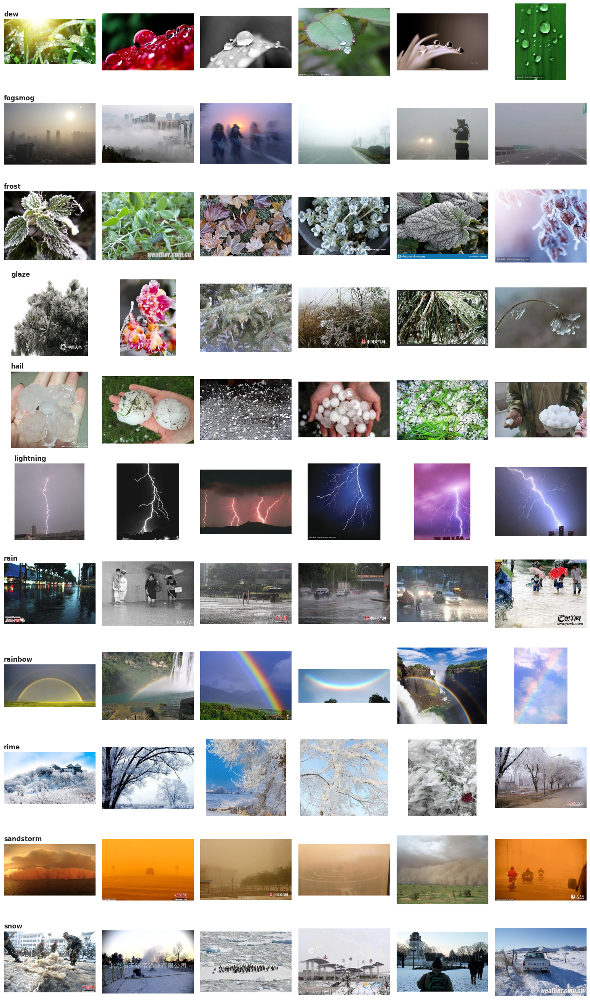

In [9]:
def get_image(path):
    item = IMAGE_CACHE.get(path)
    if item is None:
        return load_image(path, CFG.CACHE_SHORT_SIDE)
    return load_image(item) if isinstance(item, str) else item


n = CFG.SAMPLES_PER_CLASS
fig, axes = plt.subplots(CFG.NUM_CLASSES, n, figsize=(2.6 * n, 2.4 * CFG.NUM_CLASSES))
for r, c in enumerate(CFG.CLASSES):
    paths = df[df["label"] == c].sample(n, random_state=CFG.SEED)["path"].tolist()
    for k, p in enumerate(paths):
        ax = axes[r, k]
        ax.imshow(get_image(p))
        ax.axis("off")
        if k == 0:
            ax.set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 2.6 Color Statistics per Class

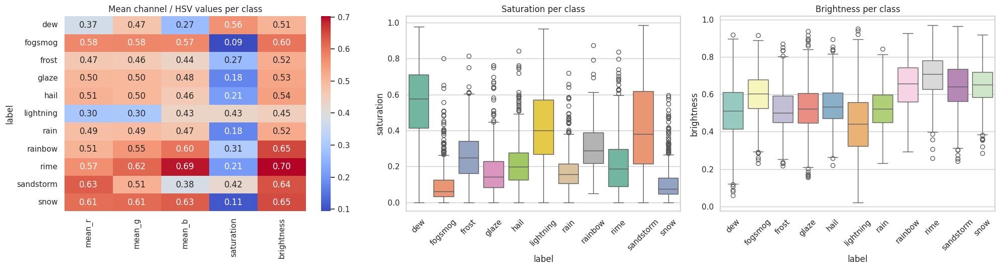

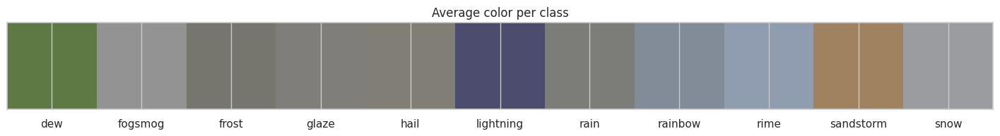

In [10]:
color = df.groupby("label")[["mean_r", "mean_g", "mean_b", "saturation", "brightness"]].mean().reindex(CFG.CLASSES)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.1, 1, 1]})
sns.heatmap(color, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Mean channel / HSV values per class")
sns.boxplot(data=df, x="label", y="saturation", ax=axes[1], palette="Set2", order=CFG.CLASSES)
axes[1].set_title("Saturation per class")
axes[1].tick_params(axis="x", rotation=45)
sns.boxplot(data=df, x="label", y="brightness", ax=axes[2], palette="Set3", order=CFG.CLASSES)
axes[2].set_title("Brightness per class")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(18, 1.6))
ax.imshow(color[["mean_r", "mean_g", "mean_b"]].values[None], aspect="auto")
ax.set_xticks(range(CFG.NUM_CLASSES), CFG.CLASSES)
ax.set_yticks([])
ax.set_title("Average color per class")
plt.show()

## 2.7 Train / Validation / Test Split

In [11]:
train_df, temp_df = train_test_split(
    df, test_size=CFG.VAL_SIZE + CFG.TEST_SIZE, stratify=df["target"], random_state=CFG.SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=CFG.TEST_SIZE / (CFG.VAL_SIZE + CFG.TEST_SIZE), stratify=temp_df["target"], random_state=CFG.SEED
)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

split_table = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(CFG.CLASSES)
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

,train,val,test
label,,,
dew,489,104,105
fogsmog,596,127,128
frost,332,72,71
glaze,447,96,96
hail,414,88,89
lightning,264,57,56
rain,368,79,79
rainbow,162,35,35
rime,812,174,174


## 2.8 Normalization Statistics

In [12]:
if CFG.NORM_STATS == "dataset":
    mean = train_df[["mean_r", "mean_g", "mean_b"]].mean().values
    std = np.sqrt(train_df[["sq_r", "sq_g", "sq_b"]].mean().values - mean**2)
    MEAN, STD = tuple(float(v) for v in mean.round(4)), tuple(float(v) for v in std.round(4))
else:
    MEAN, STD = CFG.IMAGENET_MEAN, CFG.IMAGENET_STD
print(f"Normalization ({CFG.NORM_STATS}) -> mean: {MEAN} | std: {STD}")

Normalization (dataset) -> mean: (0.5160999894142151, 0.5253000259399414, 0.5060999989509583) | std: (0.2451000064611435, 0.23309999704360962, 0.26919999718666077)


## 2.9 Transforms, Datasets & DataLoaders

In [13]:
BICUBIC = T.InterpolationMode.BICUBIC


def build_transforms(train):
    if train:
        ops = [T.RandomResizedCrop(CFG.IMG_SIZE, scale=CFG.RRC_SCALE, interpolation=BICUBIC), T.RandomHorizontalFlip()]
        if CFG.AUTO_AUGMENT == "trivial":
            ops.append(T.TrivialAugmentWide())
        elif CFG.AUTO_AUGMENT == "randaugment":
            ops.append(T.RandAugment(num_ops=2, magnitude=9))
        ops += [T.ToTensor(), T.Normalize(MEAN, STD)]
        if CFG.RANDOM_ERASING > 0:
            ops.append(T.RandomErasing(p=CFG.RANDOM_ERASING, value="random"))
        return T.Compose(ops)
    return T.Compose([
        T.Resize(int(CFG.IMG_SIZE / 0.875), interpolation=BICUBIC),
        T.CenterCrop(CFG.IMG_SIZE),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])


DISPLAY_TRANSFORM = T.Compose([T.Resize(int(CFG.IMG_SIZE / 0.875), interpolation=BICUBIC), T.CenterCrop(CFG.IMG_SIZE)])


def denormalize(t):
    t = t.detach().cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()


class WeatherDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.targets = frame["target"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        return self.transform(get_image(self.paths[idx])), self.targets[idx]


def make_loader(frame, train, batch_size=None):
    workers = CFG.NUM_WORKERS if train else CFG.EVAL_NUM_WORKERS
    return DataLoader(
        WeatherDataset(frame, build_transforms(train)),
        batch_size=batch_size or (CFG.BATCH_SIZE if train else CFG.EVAL_BATCH_SIZE),
        shuffle=train,
        num_workers=workers,
        pin_memory=DEVICE.type == "cuda",
        drop_last=train,
        persistent_workers=train and workers > 0,
        prefetch_factor=CFG.PREFETCH_FACTOR if workers > 0 else None,
    )


train_loader = make_loader(train_df, train=True)
val_loader = make_loader(val_df, train=False)
test_loader = make_loader(test_df, train=False)
xb, yb = next(iter(train_loader))
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")
print(f"Batch: {tuple(xb.shape)} | dtype: {xb.dtype} | range: [{xb.min():.2f}, {xb.max():.2f}]")

Train batches: 37 | Val batches: 9 | Test batches: 9
Batch: (128, 3, 224, 224) | dtype: torch.float32 | range: [-4.72, 4.70]


## 2.10 Augmentation Preview

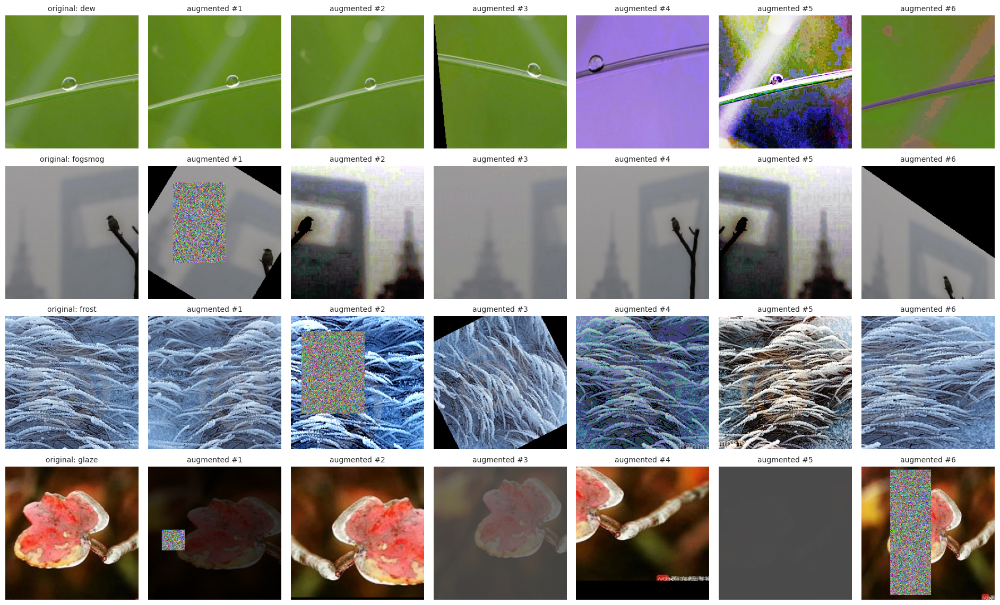

In [14]:
aug = build_transforms(train=True)
preview = train_df.groupby("label").sample(1, random_state=CFG.SEED).head(4)
fig, axes = plt.subplots(len(preview), 7, figsize=(19, 2.9 * len(preview)))
for r, (_, row) in enumerate(preview.iterrows()):
    img = get_image(row["path"])
    axes[r, 0].imshow(DISPLAY_TRANSFORM(img))
    axes[r, 0].set_title(f"original: {row['label']}", fontsize=10)
    for k in range(1, 7):
        axes[r, k].imshow(denormalize(aug(img)))
        axes[r, k].set_title(f"augmented #{k}", fontsize=10)
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout()
plt.show()

# 3. Model: FastViT

Reimplementation of *FastViT: A Fast Hybrid Vision Transformer using Structural Reparameterization* (Vasu et al., ICCV 2023):
- **Stem**: MobileOne-style reparameterizable convolutions (stride 4).
- **Stages 1–3**: RepMixer token mixer (depthwise conv mixing that folds into a single conv at inference) + ConvFFN.
- **Stage 4** (SA/MA variants): conditional positional encoding (RepCPE) + multi-head self-attention + ConvFFN.
- **Downsampling**: large-kernel (7x7) reparameterizable depthwise conv patch embedding.
- **Head**: MobileOne block with Squeeze-Excitation, global average pooling and a linear classifier.

## 3.1 Building Blocks

In [15]:
def conv_bn(in_ch, out_ch, kernel_size, stride=1, padding=0, groups=1):
    return nn.Sequential(OrderedDict([
        ("conv", nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding, groups=groups, bias=False)),
        ("bn", nn.BatchNorm2d(out_ch)),
    ]))


def fuse_bn(kernel, bn):
    std = (bn.running_var + bn.eps).sqrt()
    return kernel * (bn.weight / std).reshape(-1, 1, 1, 1), bn.bias - bn.running_mean * bn.weight / std


def identity_kernel(channels, groups, kernel_size, device, dtype):
    in_per_group = channels // groups
    kernel = torch.zeros(channels, in_per_group, kernel_size, kernel_size, device=device, dtype=dtype)
    for i in range(channels):
        kernel[i, i % in_per_group, kernel_size // 2, kernel_size // 2] = 1.0
    return kernel


def make_conv(weight, bias, stride, padding, groups):
    out_ch, in_per_group, k, _ = weight.shape
    conv = nn.Conv2d(in_per_group * groups, out_ch, k, stride, padding, groups=groups, bias=True).to(weight.device, weight.dtype)
    conv.weight.data.copy_(weight)
    conv.bias.data.copy_(bias)
    return conv


class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        if self.p == 0.0 or not self.training:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep


class SEBlock(nn.Module):
    def __init__(self, channels, rd_ratio=0.0625):
        super().__init__()
        hidden = max(8, int(channels * rd_ratio))
        self.reduce = nn.Conv2d(channels, hidden, 1)
        self.expand = nn.Conv2d(hidden, channels, 1)

    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * torch.sigmoid(self.expand(F.relu(self.reduce(s))))


class MobileOneBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0, groups=1, use_se=False,
                 use_act=True, use_scale_branch=True, num_conv_branches=1):
        super().__init__()
        self.in_ch, self.out_ch, self.kernel_size = in_ch, out_ch, kernel_size
        self.stride, self.padding, self.groups = stride, padding, groups
        self.reparameterized = False
        self.se = SEBlock(out_ch) if use_se else nn.Identity()
        self.act = nn.GELU() if use_act else nn.Identity()
        self.rbr_skip = nn.BatchNorm2d(in_ch) if in_ch == out_ch and stride == 1 else None
        self.rbr_conv = nn.ModuleList(
            [conv_bn(in_ch, out_ch, kernel_size, stride, padding, groups) for _ in range(num_conv_branches)]
        )
        self.rbr_scale = conv_bn(in_ch, out_ch, 1, stride, 0, groups) if kernel_size > 1 and use_scale_branch else None
        self.rbr_reparam = None

    def forward(self, x):
        if self.rbr_reparam is not None:
            return self.act(self.se(self.rbr_reparam(x)))
        out = self.rbr_skip(x) if self.rbr_skip is not None else 0
        if self.rbr_scale is not None:
            out = out + self.rbr_scale(x)
        for branch in self.rbr_conv:
            out = out + branch(x)
        return self.act(self.se(out))

    @torch.no_grad()
    def reparameterize(self):
        if self.reparameterized:
            return
        ref = next(self.parameters())
        k = self.kernel_size
        kernel = torch.zeros(self.out_ch, self.in_ch // self.groups, k, k, device=ref.device, dtype=ref.dtype)
        bias = torch.zeros(self.out_ch, device=ref.device, dtype=ref.dtype)
        for branch in self.rbr_conv:
            w, b = fuse_bn(branch.conv.weight, branch.bn)
            kernel, bias = kernel + w, bias + b
        if self.rbr_scale is not None:
            w, b = fuse_bn(self.rbr_scale.conv.weight, self.rbr_scale.bn)
            kernel, bias = kernel + F.pad(w, [k // 2] * 4), bias + b
        if self.rbr_skip is not None:
            w, b = fuse_bn(identity_kernel(self.in_ch, self.groups, k, ref.device, ref.dtype), self.rbr_skip)
            kernel, bias = kernel + w, bias + b
        self.rbr_reparam = make_conv(kernel, bias, self.stride, self.padding, self.groups)
        self.rbr_conv, self.rbr_scale, self.rbr_skip = nn.ModuleList(), None, None
        self.reparameterized = True


class ReparamLargeKernelConv(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride, groups, small_kernel=3):
        super().__init__()
        self.kernel_size, self.small_kernel = kernel_size, small_kernel
        self.stride, self.groups = stride, groups
        self.reparameterized = False
        self.lkb_origin = conv_bn(in_ch, out_ch, kernel_size, stride, kernel_size // 2, groups)
        self.small_conv = conv_bn(in_ch, out_ch, small_kernel, stride, small_kernel // 2, groups) if small_kernel else None
        self.act = nn.GELU()
        self.lkb_reparam = None

    def forward(self, x):
        if self.lkb_reparam is not None:
            return self.act(self.lkb_reparam(x))
        out = self.lkb_origin(x)
        if self.small_conv is not None:
            out = out + self.small_conv(x)
        return self.act(out)

    @torch.no_grad()
    def reparameterize(self):
        if self.reparameterized:
            return
        kernel, bias = fuse_bn(self.lkb_origin.conv.weight, self.lkb_origin.bn)
        if self.small_conv is not None:
            w, b = fuse_bn(self.small_conv.conv.weight, self.small_conv.bn)
            pad = (self.kernel_size - self.small_kernel) // 2
            kernel, bias = kernel + F.pad(w, [pad] * 4), bias + b
        self.lkb_reparam = make_conv(kernel, bias, self.stride, self.kernel_size // 2, self.groups)
        self.lkb_origin, self.small_conv = None, None
        self.reparameterized = True


class PatchEmbed(nn.Module):
    def __init__(self, in_ch, embed_dim, patch_size=7, stride=2):
        super().__init__()
        self.proj = nn.Sequential(
            ReparamLargeKernelConv(in_ch, embed_dim, patch_size, stride, groups=in_ch, small_kernel=3),
            MobileOneBlock(embed_dim, embed_dim, 1, 1, 0),
        )

    def forward(self, x):
        return self.proj(x)


def make_stem(in_ch, out_ch):
    return nn.Sequential(
        MobileOneBlock(in_ch, out_ch, 3, 2, 1),
        MobileOneBlock(out_ch, out_ch, 3, 2, 1, groups=out_ch),
        MobileOneBlock(out_ch, out_ch, 1, 1, 0),
    )

## 3.2 Token Mixers, Positional Encoding & ConvFFN

In [16]:
class RepMixer(nn.Module):
    def __init__(self, dim, kernel_size=3, layer_scale_init=1e-5):
        super().__init__()
        self.dim, self.kernel_size = dim, kernel_size
        self.reparameterized = False
        self.norm = MobileOneBlock(dim, dim, kernel_size, 1, kernel_size // 2, groups=dim,
                                   use_act=False, use_scale_branch=False, num_conv_branches=0)
        self.mixer = MobileOneBlock(dim, dim, kernel_size, 1, kernel_size // 2, groups=dim, use_act=False)
        self.layer_scale = nn.Parameter(layer_scale_init * torch.ones(dim, 1, 1))
        self.reparam_conv = None

    def forward(self, x):
        if self.reparam_conv is not None:
            return self.reparam_conv(x)
        return x + self.layer_scale * (self.mixer(x) - self.norm(x))

    @torch.no_grad()
    def reparameterize(self):
        if self.reparameterized:
            return
        self.mixer.reparameterize()
        self.norm.reparameterize()
        wm, bm = self.mixer.rbr_reparam.weight, self.mixer.rbr_reparam.bias
        wn, bn = self.norm.rbr_reparam.weight, self.norm.rbr_reparam.bias
        ls = self.layer_scale
        weight = identity_kernel(self.dim, self.dim, self.kernel_size, wm.device, wm.dtype) + ls.unsqueeze(-1) * (wm - wn)
        bias = ls.reshape(-1) * (bm - bn)
        self.reparam_conv = make_conv(weight, bias, 1, self.kernel_size // 2, self.dim)
        self.mixer, self.norm, self.layer_scale = None, None, None
        self.reparameterized = True


class RepCPE(nn.Module):
    def __init__(self, dim, spatial_shape=(7, 7)):
        super().__init__()
        self.dim, self.kernel_size = dim, spatial_shape[0]
        self.reparameterized = False
        self.pe = nn.Conv2d(dim, dim, spatial_shape, 1, spatial_shape[0] // 2, groups=dim, bias=True)
        self.reparam_conv = None

    def forward(self, x):
        if self.reparam_conv is not None:
            return self.reparam_conv(x)
        return x + self.pe(x)

    @torch.no_grad()
    def reparameterize(self):
        if self.reparameterized:
            return
        w = self.pe.weight
        weight = w + identity_kernel(self.dim, self.dim, self.kernel_size, w.device, w.dtype)
        self.reparam_conv = make_conv(weight, self.pe.bias, 1, self.kernel_size // 2, self.dim)
        self.pe = None
        self.reparameterized = True


class Attention(nn.Module):
    def __init__(self, dim, head_dim=32, qkv_bias=False, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.num_heads = max(1, dim // head_dim)
        self.head_dim = dim // self.num_heads
        self.attn_drop = attn_drop
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x):
        B, C, H, W = x.shape
        tokens = x.flatten(2).transpose(1, 2)
        qkv = self.qkv(tokens).reshape(B, H * W, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)
        out = F.scaled_dot_product_attention(q, k, v, dropout_p=self.attn_drop if self.training else 0.0)
        out = self.proj_drop(self.proj(out.transpose(1, 2).reshape(B, H * W, C)))
        return out.transpose(1, 2).reshape(B, C, H, W)


class ConvFFN(nn.Module):
    def __init__(self, dim, hidden_dim, drop=0.0):
        super().__init__()
        self.conv = conv_bn(dim, dim, 7, 1, 3, groups=dim)
        self.fc1 = nn.Conv2d(dim, hidden_dim, 1)
        self.act = nn.GELU()
        self.fc2 = nn.Conv2d(hidden_dim, dim, 1)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = self.drop(self.act(self.fc1(self.conv(x))))
        return self.drop(self.fc2(x))

## 3.3 FastViT Blocks & Stages

In [17]:
class RepMixerBlock(nn.Module):
    def __init__(self, dim, kernel_size=3, mlp_ratio=3.0, drop=0.0, drop_path=0.0, layer_scale_init=1e-5):
        super().__init__()
        self.token_mixer = RepMixer(dim, kernel_size, layer_scale_init)
        self.convffn = ConvFFN(dim, int(dim * mlp_ratio), drop)
        self.layer_scale = nn.Parameter(layer_scale_init * torch.ones(dim, 1, 1))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        x = self.token_mixer(x)
        return x + self.drop_path(self.layer_scale * self.convffn(x))


class AttentionBlock(nn.Module):
    def __init__(self, dim, mlp_ratio=4.0, drop=0.0, drop_path=0.0, layer_scale_init=1e-5):
        super().__init__()
        self.norm = nn.BatchNorm2d(dim)
        self.token_mixer = Attention(dim)
        self.convffn = ConvFFN(dim, int(dim * mlp_ratio), drop)
        self.layer_scale_1 = nn.Parameter(layer_scale_init * torch.ones(dim, 1, 1))
        self.layer_scale_2 = nn.Parameter(layer_scale_init * torch.ones(dim, 1, 1))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        x = x + self.drop_path(self.layer_scale_1 * self.token_mixer(self.norm(x)))
        return x + self.drop_path(self.layer_scale_2 * self.convffn(x))


class FastViTStage(nn.Module):
    def __init__(self, in_dim, dim, depth, token_mixer, mlp_ratio, downsample, use_pos_emb,
                 kernel_size, down_patch_size, down_stride, drop, drop_paths, layer_scale_init):
        super().__init__()
        self.downsample = PatchEmbed(in_dim, dim, down_patch_size, down_stride) if downsample else nn.Identity()
        self.pos_emb = RepCPE(dim) if use_pos_emb else nn.Identity()
        blocks = []
        for i in range(depth):
            if token_mixer == "repmixer":
                blocks.append(RepMixerBlock(dim, kernel_size, mlp_ratio, drop, drop_paths[i], layer_scale_init))
            elif token_mixer == "attention":
                blocks.append(AttentionBlock(dim, mlp_ratio, drop, drop_paths[i], layer_scale_init))
            else:
                raise ValueError(f"Unknown token mixer: {token_mixer}")
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x):
        return self.blocks(self.pos_emb(self.downsample(x)))

## 3.4 FastViT Network

In [18]:
class FastViT(nn.Module):
    def __init__(self, layers, embed_dims, mlp_ratios, token_mixers, pos_embs, num_classes=1000, in_chans=3,
                 repmixer_kernel_size=3, down_patch_size=7, down_stride=2, drop_rate=0.0, drop_path_rate=0.0,
                 layer_scale_init=1e-5, cls_ratio=2.0):
        super().__init__()
        self.stem = make_stem(in_chans, embed_dims[0])
        dpr = torch.linspace(0, drop_path_rate, sum(layers)).tolist()
        stages, cursor, prev_dim = [], 0, embed_dims[0]
        for i, depth in enumerate(layers):
            stages.append(FastViTStage(
                prev_dim, embed_dims[i], depth, token_mixers[i], mlp_ratios[i],
                downsample=i > 0, use_pos_emb=pos_embs[i], kernel_size=repmixer_kernel_size,
                down_patch_size=down_patch_size, down_stride=down_stride, drop=drop_rate,
                drop_paths=dpr[cursor:cursor + depth], layer_scale_init=layer_scale_init,
            ))
            cursor += depth
            prev_dim = embed_dims[i]
        self.stages = nn.Sequential(*stages)
        self.num_features = int(embed_dims[-1] * cls_ratio)
        self.conv_exp = MobileOneBlock(embed_dims[-1], self.num_features, 3, 1, 1, groups=embed_dims[-1], use_se=True)
        self.head_drop = nn.Dropout(drop_rate)
        self.head = nn.Linear(self.num_features, num_classes)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward_features(self, x):
        return self.conv_exp(self.stages(self.stem(x)))

    def forward_head(self, x):
        return self.head(self.head_drop(F.adaptive_avg_pool2d(x, 1).flatten(1)))

    def forward(self, x):
        return self.forward_head(self.forward_features(x))

## 3.5 Variants & Factory

In [19]:
def _variant(layers, dims, mlp, mixers=("repmixer",) * 4, pos=(False,) * 4):
    return dict(layers=layers, embed_dims=dims, mlp_ratios=(mlp,) * 4, token_mixers=mixers, pos_embs=pos)


ATTN_LAST = ("repmixer", "repmixer", "repmixer", "attention")
CPE_LAST = (False, False, False, True)
FASTVIT_VARIANTS = {
    "fastvit_t8": _variant((2, 2, 4, 2), (48, 96, 192, 384), 3),
    "fastvit_t12": _variant((2, 2, 6, 2), (64, 128, 256, 512), 3),
    "fastvit_s12": _variant((2, 2, 6, 2), (64, 128, 256, 512), 4),
    "fastvit_sa12": _variant((2, 2, 6, 2), (64, 128, 256, 512), 4, ATTN_LAST, CPE_LAST),
    "fastvit_sa24": _variant((4, 4, 12, 4), (64, 128, 256, 512), 4, ATTN_LAST, CPE_LAST),
    "fastvit_sa36": _variant((6, 6, 18, 6), (64, 128, 256, 512), 4, ATTN_LAST, CPE_LAST),
    "fastvit_ma36": _variant((6, 6, 18, 6), (76, 152, 304, 608), 4, ATTN_LAST, CPE_LAST),
}


def create_fastvit(variant=None, num_classes=None, **overrides):
    variant = variant or CFG.MODEL_VARIANT
    kwargs = dict(
        num_classes=num_classes or CFG.NUM_CLASSES,
        drop_rate=CFG.DROP_RATE,
        drop_path_rate=CFG.DROP_PATH_RATE,
        layer_scale_init=CFG.LAYER_SCALE_INIT,
        cls_ratio=CFG.CLS_RATIO,
    )
    kwargs.update(overrides)
    return FastViT(**FASTVIT_VARIANTS[variant], **kwargs)

## 3.6 Structural Reparameterization

At inference every multi-branch block (MobileOne, RepMixer, RepCPE, large-kernel conv) collapses into a single convolution, producing an identical function with fewer layers and lower latency.

In [20]:
def reparameterize_model(model):
    model = copy.deepcopy(unwrap(model)).eval()
    for m in list(model.modules()):
        if hasattr(m, "reparameterize"):
            m.reparameterize()
    return model

# 4. Model Info

## 4.1 Parameters & FLOPs

In [21]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


@torch.no_grad()
def count_flops(model, img_size):
    model.eval()
    with FlopCounterMode(display=False) as counter:
        model(torch.zeros(1, 3, img_size, img_size, device=next(model.parameters()).device))
    return counter.get_total_flops()


def count_layers(model, kind=nn.Conv2d):
    return sum(isinstance(m, kind) for m in model.modules())


model = create_fastvit()
model_reparam = reparameterize_model(model)

TIMM_REFERENCE_M = {"fastvit_t8": 4.0, "fastvit_t12": 7.6, "fastvit_s12": 9.5, "fastvit_sa12": 11.6,
                    "fastvit_sa24": 21.6, "fastvit_sa36": 31.5, "fastvit_ma36": 44.1}
reference = pd.DataFrame({
    "ours, 1000-class head (M)": {n: count_params(create_fastvit(n, num_classes=1000)) / 1e6 for n in FASTVIT_VARIANTS},
    "timm reference (M)": TIMM_REFERENCE_M,
}).round(2)
display(reference.T)

info = pd.DataFrame({
    "train-time": {
        "params (M)": count_params(model) / 1e6,
        "trainable (M)": count_params(model, True) / 1e6,
        "GFLOPs": count_flops(model, CFG.IMG_SIZE) / 1e9,
        "conv layers": count_layers(model),
        "BN layers": count_layers(model, nn.BatchNorm2d),
    },
    "reparameterized": {
        "params (M)": count_params(model_reparam) / 1e6,
        "trainable (M)": count_params(model_reparam, True) / 1e6,
        "GFLOPs": count_flops(model_reparam, CFG.IMG_SIZE) / 1e9,
        "conv layers": count_layers(model_reparam),
        "BN layers": count_layers(model_reparam, nn.BatchNorm2d),
    },
}).round(3)
print(f"Variant: {CFG.MODEL_VARIANT} | input: 3x{CFG.IMG_SIZE}x{CFG.IMG_SIZE} | classes: {CFG.NUM_CLASSES}")
display(info)

,fastvit_t8,fastvit_t12,fastvit_s12,fastvit_sa12,fastvit_sa24,fastvit_sa36,fastvit_ma36
"ours, 1000-class head (M)",4.03,7.55,9.47,11.58,21.55,31.53,44.07
timm reference (M),4.00,7.60,9.50,11.60,21.60,31.50,44.10


Variant: fastvit_sa12 | input: 3x224x224 | classes: 11


,train-time,reparameterized
params (M),10.567,10.532
trainable (M),10.567,10.532
GFLOPs,2.962,2.952
conv layers,75.000,59.000
BN layers,74.000,14.000


## 4.2 Stage Configuration

In [22]:
spec = FASTVIT_VARIANTS[CFG.MODEL_VARIANT]
stage_table = pd.DataFrame([
    {
        "stage": i + 1,
        "depth": spec["layers"][i],
        "dim": spec["embed_dims"][i],
        "token_mixer": spec["token_mixers"][i],
        "mlp_ratio": spec["mlp_ratios"][i],
        "pos_emb": "RepCPE" if spec["pos_embs"][i] else "-",
        "stride": 4 * 2**i,
        "feature_map": f"{CFG.IMG_SIZE // (4 * 2**i)}x{CFG.IMG_SIZE // (4 * 2**i)}",
        "params (M)": round(count_params(model.stages[i]) / 1e6, 3),
    }
    for i in range(len(spec["layers"]))
])
display(stage_table)
print(model.stages[0].blocks[0])
print(model.stages[-1].blocks[0])

,stage,depth,dim,token_mixer,mlp_ratio,pos_emb,stride,feature_map,params (M)
0,1,2,64,repmixer,4,-,4,56x56,0.075
1,2,2,128,repmixer,4,-,8,28x28,0.306
2,3,6,256,repmixer,4,-,16,14x14,3.345
3,4,2,512,attention,4,RepCPE,32,7x7,6.675


RepMixerBlock(
  (token_mixer): RepMixer(
    (norm): MobileOneBlock(
      (se): Identity()
      (act): Identity()
      (rbr_skip): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rbr_conv): ModuleList()
    )
    (mixer): MobileOneBlock(
      (se): Identity()
      (act): Identity()
      (rbr_skip): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rbr_conv): ModuleList(
        (0): Sequential(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
          (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (rbr_scale): Sequential(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), groups=64, bias=False)
        (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
  )
  (convffn): ConvFFN(
    (conv): Sequential(
      (conv): Conv2d

## 4.3 Layer-wise Output Shapes

In [23]:
@torch.no_grad()
def layer_summary(model, img_size):
    rows, hooks = [], []
    named = [("stem", model.stem)]
    for i, stage in enumerate(model.stages):
        named += [(f"stages.{i}.downsample", stage.downsample), (f"stages.{i}.pos_emb", stage.pos_emb)]
        named += [(f"stages.{i}.blocks.{j}", b) for j, b in enumerate(stage.blocks)]
    named += [("conv_exp", model.conv_exp), ("head", model.head)]
    for name, module in named:
        if isinstance(module, nn.Identity):
            continue
        hooks.append(module.register_forward_hook(
            lambda m, inp, out, name=name: rows.append({
                "module": name,
                "type": type(m).__name__,
                "input_shape": tuple(inp[0].shape),
                "output_shape": tuple(out.shape),
                "params": count_params(m),
            })
        ))
    model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


summary = layer_summary(model, CFG.IMG_SIZE)
pd.set_option("display.max_rows", 200)
display(summary)

,module,type,input_shape,output_shape,params
0,stem,Sequential,"(1, 3, 224, 224)","(1, 64, 56, 56)",7424
1,stages.0.blocks.0,RepMixerBlock,"(1, 64, 56, 56)","(1, 64, 56, 56)",37632
2,stages.0.blocks.1,RepMixerBlock,"(1, 64, 56, 56)","(1, 64, 56, 56)",37632
3,stages.1.downsample,PatchEmbed,"(1, 64, 56, 56)","(1, 128, 28, 28)",24832
4,stages.1.blocks.0,RepMixerBlock,"(1, 128, 28, 28)","(1, 128, 28, 28)",140800
5,stages.1.blocks.1,RepMixerBlock,"(1, 128, 28, 28)","(1, 128, 28, 28)",140800
6,stages.2.downsample,PatchEmbed,"(1, 128, 28, 28)","(1, 256, 14, 14)",82432
7,stages.2.blocks.0,RepMixerBlock,"(1, 256, 14, 14)","(1, 256, 14, 14)",543744
8,stages.2.blocks.1,RepMixerBlock,"(1, 256, 14, 14)","(1, 256, 14, 14)",543744
9,stages.2.blocks.2,RepMixerBlock,"(1, 256, 14, 14)","(1, 256, 14, 14)",543744


## 4.4 Reparameterization Equivalence Check

In [24]:
@torch.no_grad()
def randomize_for_check(model):
    model = copy.deepcopy(model)
    for name, p in model.named_parameters():
        if "layer_scale" in name:
            p.uniform_(0.2, 1.0)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.running_mean.uniform_(-0.2, 0.2)
            m.running_var.uniform_(0.5, 1.5)
            m.weight.uniform_(0.5, 1.5)
            m.bias.uniform_(-0.2, 0.2)
    return model.eval()


check_model = randomize_for_check(model)
check_reparam = reparameterize_model(check_model)
x = torch.randn(4, 3, CFG.IMG_SIZE, CFG.IMG_SIZE)
with torch.no_grad():
    y_train, y_infer = check_model(x), check_reparam(x)
print(f"Max |logits_train - logits_reparam| = {(y_train - y_infer).abs().max().item():.2e}")
print(f"Same argmax: {torch.equal(y_train.argmax(1), y_infer.argmax(1))}")
del check_model, check_reparam, model_reparam
gc.collect()

Max |logits_train - logits_reparam| = 7.45e-08
Same argmax: True


24256

# 5. Training

## 5.1 Mixup / CutMix

In [25]:
class MixupCutmix:
    def __init__(self, num_classes, mixup_alpha, cutmix_alpha, prob, switch_prob, smoothing):
        self.num_classes = num_classes
        self.mixup_alpha, self.cutmix_alpha = mixup_alpha, cutmix_alpha
        self.prob, self.switch_prob, self.smoothing = prob, switch_prob, smoothing

    def one_hot(self, y):
        off = self.smoothing / self.num_classes
        targets = torch.full((y.size(0), self.num_classes), off, device=y.device)
        return targets.scatter_(1, y.unsqueeze(1), 1.0 - self.smoothing + off)

    def __call__(self, x, y, enabled=True):
        targets = self.one_hot(y)
        if not enabled or np.random.rand() > self.prob or (self.mixup_alpha <= 0 and self.cutmix_alpha <= 0):
            return x, targets
        perm = torch.randperm(x.size(0), device=x.device)
        use_cutmix = self.cutmix_alpha > 0 and (self.mixup_alpha <= 0 or np.random.rand() < self.switch_prob)
        if use_cutmix:
            lam = np.random.beta(self.cutmix_alpha, self.cutmix_alpha)
            H, W = x.shape[-2:]
            ch, cw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
            cy, cx = np.random.randint(H), np.random.randint(W)
            y1, y2 = np.clip(cy - ch // 2, 0, H), np.clip(cy + ch // 2, 0, H)
            x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
            x = x.clone()
            x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
            lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
        else:
            lam = np.random.beta(self.mixup_alpha, self.mixup_alpha)
            x = lam * x + (1 - lam) * x[perm]
        return x, lam * targets + (1 - lam) * targets[perm]

## 5.2 Model EMA

In [26]:
class ModelEMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(unwrap(model)).eval()
        self.decay = decay
        self.updates = 0
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        source = unwrap(model).state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(source[k].detach(), alpha=1 - d)
            else:
                v.copy_(source[k])

## 5.3 Loss, Optimizer & Scheduler

In [27]:
def compute_class_weights(frame):
    counts = np.bincount(frame["target"], minlength=CFG.NUM_CLASSES).astype(np.float64)
    w = counts.sum() / (CFG.NUM_CLASSES * counts)
    w = np.minimum(w, w.min() * CFG.CLASS_WEIGHT_CLIP)
    return torch.tensor(w / w.mean(), dtype=torch.float32)


def param_groups(model, weight_decay):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim <= 1 or name.endswith(".bias") or "layer_scale" in name:
            no_decay.append(p)
        else:
            decay.append(p)
    return [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]


def warmup_cosine(optimizer, total_steps, warmup_steps, min_ratio):
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


class_weights = compute_class_weights(train_df) if CFG.USE_CLASS_WEIGHTS else None
if class_weights is not None:
    display(pd.DataFrame({"class": CFG.CLASSES, "weight": class_weights.numpy().round(3)}).set_index("class").T)

class,dew,fogsmog,frost,glaze,hail,lightning,rain,rainbow,rime,sandstorm,snow
weight,0.759,0.623,1.118,0.83,0.896,1.405,1.008,2.285,0.457,0.767,0.853


## 5.4 Train & Validation Loops

In [28]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler, scaler, ema, mixer, mix_enabled):
    model.train()
    loss_sum, correct, seen = 0.0, 0, 0
    pbar = tqdm(loader, desc="train", leave=False)
    for x, y in pbar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        x, targets = mixer(x, y, mix_enabled)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = model(x)
        loss = criterion(logits.float(), targets)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= scale_before:
            scheduler.step()
        if ema is not None:
            ema.update(model)

        bs = y.size(0)
        loss_sum += loss.item() * bs
        correct += (logits.argmax(1) == targets.argmax(1)).sum().item()
        seen += bs
        pbar.set_postfix(loss=f"{loss_sum / seen:.4f}", lr=f"{optimizer.param_groups[0]['lr']:.2e}")
    return loss_sum / seen, correct / seen


@torch.no_grad()
def predict(model, loader, tta=False, desc="predict"):
    model.eval()
    all_probs, all_targets = [], []
    for x, y in tqdm(loader, desc=desc, leave=False):
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            probs = model(x).float().softmax(1)
            if tta:
                probs = (probs + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        all_probs.append(probs.cpu())
        all_targets.append(y)
    return torch.cat(all_probs).numpy(), torch.cat(all_targets).numpy()


def compute_metrics(probs, targets):
    preds = probs.argmax(1)
    nll = -np.log(np.clip(probs[np.arange(len(targets)), targets], 1e-12, 1.0)).mean()
    return {
        "loss": float(nll),
        "acc": accuracy_score(targets, preds),
        "f1": f1_score(targets, preds, average="macro"),
    }

## 5.5 Run Training

In [29]:
def fit():
    seed_everything(CFG.SEED)
    net = create_fastvit().to(DEVICE)
    train_model = maybe_parallel(net)
    ema = ModelEMA(net, CFG.EMA_DECAY) if CFG.USE_EMA else None
    eval_target = ema.module if ema is not None else net
    eval_model = maybe_parallel(eval_target)

    criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE) if class_weights is not None else None)
    optimizer = torch.optim.AdamW(param_groups(net, CFG.WEIGHT_DECAY), lr=CFG.LR, betas=(0.9, 0.999))
    steps_per_epoch = len(train_loader)
    scheduler = warmup_cosine(optimizer, CFG.EPOCHS * steps_per_epoch, CFG.WARMUP_EPOCHS * steps_per_epoch, CFG.MIN_LR / CFG.LR)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    mixer = MixupCutmix(CFG.NUM_CLASSES, CFG.MIXUP_ALPHA, CFG.CUTMIX_ALPHA, CFG.MIX_PROB, CFG.MIX_SWITCH_PROB, CFG.LABEL_SMOOTHING)

    ckpt_path = os.path.join(CFG.OUTPUT_DIR, CFG.CHECKPOINT_NAME)
    history, best_score, best_epoch, bad_epochs = [], -np.inf, 0, 0
    print(f"{'epoch':>5} | {'lr':>8} | {'train_loss':>10} | {'train_acc':>9} | {'val_loss':>8} | {'val_acc':>7} | {'val_f1':>6} | {'time':>6} | {'ram_main':>8} | {'ram_workers':>11}")
    for epoch in range(1, CFG.EPOCHS + 1):
        t0 = time.time()
        mix_enabled = epoch <= CFG.EPOCHS - CFG.MIX_OFF_LAST_EPOCHS
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc = train_one_epoch(train_model, train_loader, criterion, optimizer, scheduler, scaler, ema, mixer, mix_enabled)
        probs, targets = predict(eval_model, val_loader, desc="val")
        val = compute_metrics(probs, targets)
        if CFG.RELEASE_MEMORY_EVERY_EPOCH:
            release_memory()
        ram_main, ram_workers = ram_gb()
        row = {
            "epoch": epoch, "lr": lr, "train_loss": train_loss, "train_acc": train_acc,
            "val_loss": val["loss"], "val_acc": val["acc"], "val_f1": val["f1"], "time": time.time() - t0, "ram_main": ram_main, "ram_workers": ram_workers,
        }
        history.append(row)

        improved = row[CFG.MONITOR] > best_score
        if improved:
            best_score, best_epoch, bad_epochs = row[CFG.MONITOR], epoch, 0
            torch.save({
                "state_dict": eval_target.state_dict(),
                "variant": CFG.MODEL_VARIANT,
                "classes": CFG.CLASSES,
                "mean": MEAN,
                "std": STD,
                "img_size": CFG.IMG_SIZE,
                "epoch": epoch,
                "metrics": row,
            }, ckpt_path)
        else:
            bad_epochs += 1
        print(f"{epoch:>5} | {lr:>8.2e} | {train_loss:>10.4f} | {train_acc:>9.4f} | {row['val_loss']:>8.4f} | "
              f"{row['val_acc']:>7.4f} | {row['val_f1']:>6.4f} | {row['time']:>5.1f}s | {ram_main:>6.2f}GB | {ram_workers:>9.2f}GB {'*' if improved else ''}")
        if bad_epochs >= CFG.PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

    print(f"Best {CFG.MONITOR}: {best_score:.4f} at epoch {best_epoch} -> {ckpt_path}")
    return pd.DataFrame(history), ckpt_path


history, CKPT_PATH = fit()
history.to_csv(os.path.join(CFG.OUTPUT_DIR, "history.csv"), index=False)
torch.cuda.empty_cache()

epoch |       lr | train_loss | train_acc | val_loss | val_acc | val_f1 |   time | ram_main | ram_workers


train:   0%|          | 0/37 [00:00<?, ?it/s]

val:   0%|          | 0/9 [00:00<?, ?it/s]

    1 | 5.41e-06 |     2.0590 |    0.1220 |   2.3535 |  0.1166 | 0.1244 |  80.4s |   2.38GB |      0.07GB *


train:   0%|          | 0/37 [00:00<?, ?it/s]

...

val:   0%|          | 0/9 [00:00<?, ?it/s]

  119 | 1.77e-06 |     0.6775 |    0.9046 |   0.4470 |  0.8824 | 0.8912 |  46.0s |   2.38GB |      0.07GB 


train:   0%|          | 0/37 [00:00<?, ?it/s]

val:   0%|          | 0/9 [00:00<?, ?it/s]

  120 | 1.20e-06 |     0.6775 |    0.9033 |   0.4449 |  0.8814 | 0.8903 |  46.1s |   2.38GB |      0.07GB 
Best val_f1: 0.8948 at epoch 107 -> /kaggle/working/fastvit_weather_best.pth


## 5.6 Training Curves

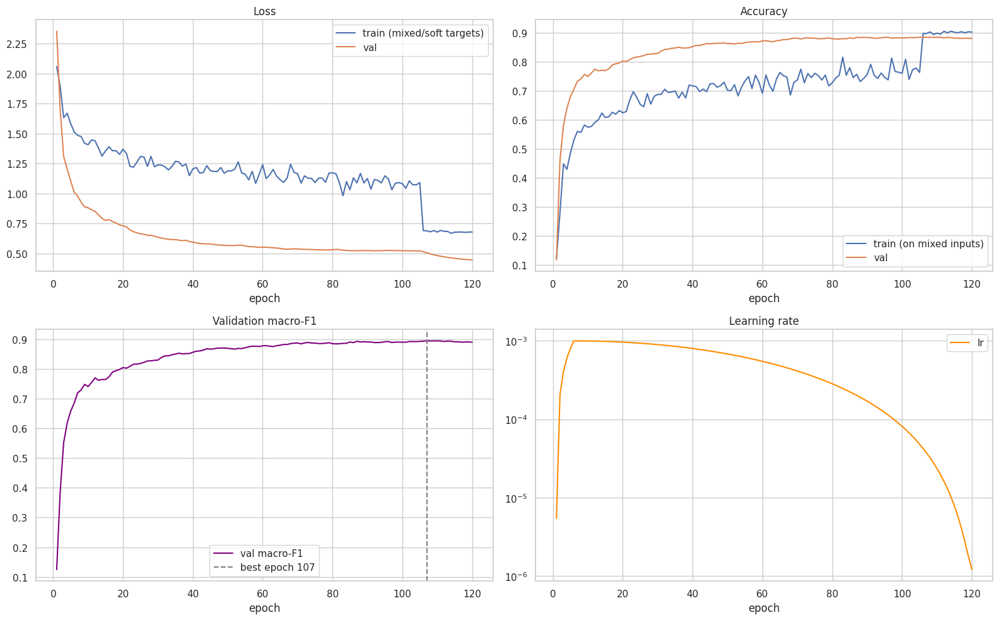

,epoch,lr,train_loss,train_acc,val_loss,val_acc,val_f1,time,ram_main,ram_workers
106,107,0.0,0.6882,0.8984,0.5043,0.8853,0.8948,46.0656,2.3805,0.0671
107,108,0.0,0.6796,0.9039,0.4957,0.8853,0.8947,46.0955,2.3805,0.0671
109,110,0.0,0.6773,0.8997,0.4815,0.8853,0.8947,45.6891,2.3805,0.0671
108,109,0.0,0.6902,0.8951,0.4880,0.8853,0.8947,45.5099,2.3806,0.0671
110,111,0.0,0.6912,0.8963,0.4759,0.8853,0.8947,45.6042,2.3806,0.0671


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].plot(history["epoch"], history["train_loss"], label="train (mixed/soft targets)")
axes[0, 0].plot(history["epoch"], history["val_loss"], label="val")
axes[0, 0].set_title("Loss")
axes[0, 1].plot(history["epoch"], history["train_acc"], label="train (on mixed inputs)")
axes[0, 1].plot(history["epoch"], history["val_acc"], label="val")
axes[0, 1].set_title("Accuracy")
axes[1, 0].plot(history["epoch"], history["val_f1"], color="purple", label="val macro-F1")
best = history.loc[history[CFG.MONITOR].idxmax()]
axes[1, 0].axvline(best["epoch"], ls="--", c="gray", label=f"best epoch {int(best['epoch'])}")
axes[1, 0].set_title("Validation macro-F1")
axes[1, 1].plot(history["epoch"], history["lr"], color="darkorange", label="lr")
axes[1, 1].set(yscale="log", title="Learning rate")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()
display(history.sort_values(CFG.MONITOR, ascending=False).head(5).round(4))

# 6. Evaluation (Validation Set)

## 6.1 Load Best Model & Reparameterize

In [31]:
ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
best_model = create_fastvit(ckpt["variant"], len(ckpt["classes"]))
best_model.load_state_dict(ckpt["state_dict"])
best_model = best_model.to(DEVICE).eval()
infer_model = reparameterize_model(best_model)
print(f"Loaded epoch {ckpt['epoch']} | metrics: { {k: round(v, 4) for k, v in ckpt['metrics'].items()} }")

xb, _ = next(iter(val_loader))
with torch.no_grad():
    xb = xb[:32].to(DEVICE)
    diff = (best_model(xb) - infer_model(xb)).abs().max().item()
print(f"Reparameterization max logit diff on real images: {diff:.2e}")
INFER = maybe_parallel(infer_model)

Loaded epoch 107 | metrics: {'epoch': 107, 'lr': 0.0, 'train_loss': 0.6882, 'train_acc': 0.8984, 'val_loss': 0.5043, 'val_acc': 0.8853, 'val_f1': 0.8948, 'time': 46.0656, 'ram_main': 2.3805, 'ram_workers': 0.0671}
Reparameterization max logit diff on real images: 3.64e-06


## 6.2 Metrics & Classification Report

In [32]:
def report(probs, targets, title):
    preds = probs.argmax(1)
    labels = list(range(CFG.NUM_CLASSES))
    summary = {
        "accuracy": accuracy_score(targets, preds),
        f"top-{CFG.TOP_K} accuracy": top_k_accuracy_score(targets, probs, k=CFG.TOP_K, labels=labels),
        "macro F1": f1_score(targets, preds, average="macro"),
        "weighted F1": f1_score(targets, preds, average="weighted"),
        "macro ROC-AUC (OvR)": roc_auc_score(targets, probs, multi_class="ovr", average="macro", labels=labels),
        "NLL": compute_metrics(probs, targets)["loss"],
    }
    print(f"===== {title} =====")
    display(pd.DataFrame(summary, index=[title]).round(4))
    rep = classification_report(targets, preds, target_names=CFG.CLASSES, output_dict=True, digits=4)
    display(pd.DataFrame(rep).T.round(4).style.background_gradient(cmap="Greens", subset=["precision", "recall", "f1-score"]))
    return preds


val_probs, val_targets = predict(INFER, val_loader, tta=CFG.TTA, desc="val")
val_preds = report(val_probs, val_targets, f"Validation (TTA={CFG.TTA})")

val:   0%|          | 0/9 [00:00<?, ?it/s]

===== Validation (TTA=True) =====


,accuracy,top-3 accuracy,macro F1,weighted F1,macro ROC-AUC (OvR),NLL
Validation (TTA=True),0.8834,0.9874,0.8908,0.8839,0.9911,0.4985


,precision,recall,f1-score,support
dew,0.969100,0.903800,0.935300,104.000000
fogsmog,0.951200,0.921300,0.936000,127.000000
frost,0.776300,0.819400,0.797300,72.000000
glaze,0.726400,0.802100,0.762400,96.000000
hail,0.884200,0.954500,0.918000,88.000000
lightning,0.982800,1.000000,0.991300,57.000000
rain,0.958300,0.873400,0.913900,79.000000
rainbow,0.945900,1.000000,0.972200,35.000000
rime,0.881000,0.850600,0.865500,174.000000
sandstorm,0.881800,0.932700,0.906500,104.000000


## 6.3 Confusion Matrix

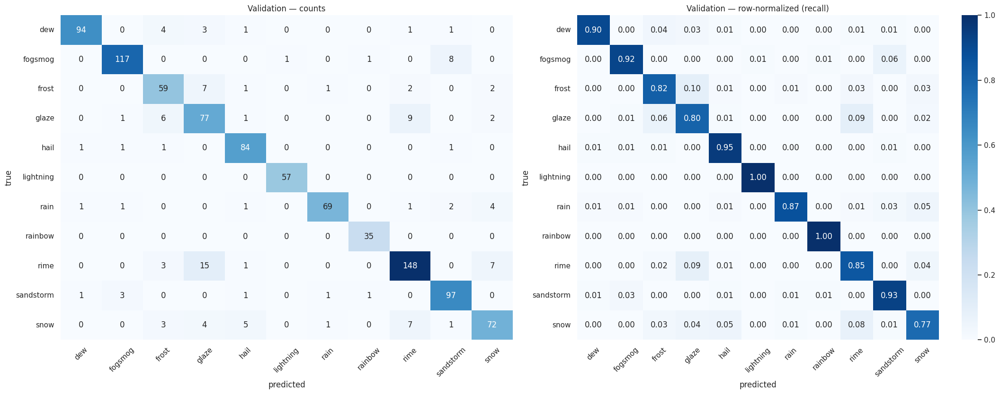

Top confusions (true -> predicted : rate):
       frost -> glaze     : 0.097
       glaze -> rime      : 0.094
        rime -> glaze     : 0.086
        snow -> rime      : 0.075
     fogsmog -> sandstorm : 0.063
       glaze -> frost     : 0.062
        snow -> hail      : 0.054
        rain -> snow      : 0.051


In [33]:
def plot_confusion(targets, preds, title):
    cm = confusion_matrix(targets, preds, labels=range(CFG.NUM_CLASSES))
    cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(22, 8.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CFG.CLASSES, yticklabels=CFG.CLASSES, ax=axes[0], cbar=False)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CFG.CLASSES, yticklabels=CFG.CLASSES, ax=axes[1], vmin=0, vmax=1)
    for ax, sub in zip(axes, ["counts", "row-normalized (recall)"]):
        ax.set(xlabel="predicted", ylabel="true", title=f"{title} — {sub}")
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
    off = pd.DataFrame(cm_norm, index=CFG.CLASSES, columns=CFG.CLASSES).stack()
    off = off[[a != b for a, b in off.index]].sort_values(ascending=False).head(8)
    print("Top confusions (true -> predicted : rate):")
    for (t, p), v in off.items():
        print(f"  {t:>10} -> {p:<10}: {v:.3f}")


plot_confusion(val_targets, val_preds, "Validation")

## 6.4 Per-class Metrics & ROC-AUC

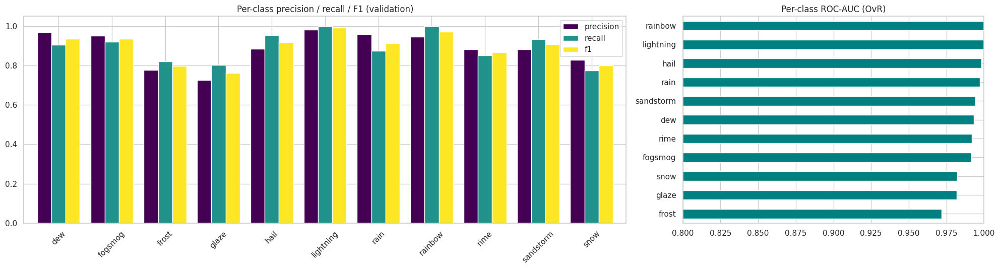

,precision,recall,f1,roc_auc,support
dew,0.9691,0.9038,0.9353,0.9931,104
fogsmog,0.9512,0.9213,0.9360,0.9916,127
frost,0.7763,0.8194,0.7973,0.9719,72
glaze,0.7264,0.8021,0.7624,0.9818,96
hail,0.8842,0.9545,0.9180,0.9981,88
lightning,0.9828,1.0000,0.9913,0.9998,57
rain,0.9583,0.8734,0.9139,0.9973,79
rainbow,0.9459,1.0000,0.9722,1.0000,35
rime,0.8810,0.8506,0.8655,0.9918,174
sandstorm,0.8818,0.9327,0.9065,0.9942,104


In [34]:
def per_class_table(probs, targets):
    preds = probs.argmax(1)
    p, r, f, s = precision_recall_fscore_support(targets, preds, labels=range(CFG.NUM_CLASSES), zero_division=0)
    one_hot = np.eye(CFG.NUM_CLASSES)[targets]
    auc = [roc_auc_score(one_hot[:, k], probs[:, k]) if 0 < one_hot[:, k].sum() < len(targets) else np.nan for k in range(CFG.NUM_CLASSES)]
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "roc_auc": auc, "support": s}, index=CFG.CLASSES)


pc = per_class_table(val_probs, val_targets)
fig, axes = plt.subplots(1, 2, figsize=(20, 5.5), gridspec_kw={"width_ratios": [2, 1]})
pc[["precision", "recall", "f1"]].plot.bar(ax=axes[0], width=0.8, colormap="viridis")
axes[0].set(ylim=(0, 1.05), title="Per-class precision / recall / F1 (validation)")
axes[0].tick_params(axis="x", rotation=45)
pc["roc_auc"].sort_values().plot.barh(ax=axes[1], color="teal")
axes[1].set(xlim=(min(0.8, pc["roc_auc"].min() - 0.02), 1.0), title="Per-class ROC-AUC (OvR)")
plt.tight_layout()
plt.show()
display(pc.round(4))

## 6.5 Inference Speed: Train-time vs Reparameterized

In [35]:
@torch.no_grad()
def benchmark(model, batch_size, device, runs=CFG.BENCHMARK_RUNS, warmup=10):
    model = copy.deepcopy(unwrap(model)).to(device).eval()
    x = torch.randn(batch_size, 3, CFG.IMG_SIZE, CFG.IMG_SIZE, device=device)
    for _ in range(warmup):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / runs


settings = [(torch.device("cpu"), 1)]
if DEVICE.type == "cuda":
    settings = [(DEVICE, 1), (DEVICE, 64)] + settings
rows = []
for device, bs in settings:
    t_train = benchmark(best_model, bs, device)
    t_infer = benchmark(infer_model, bs, device)
    rows.append({"device": device.type, "batch": bs, "train-time (ms)": t_train, "reparameterized (ms)": t_infer,
                 "speedup": t_train / t_infer, "imgs/s reparam": 1000 * bs / t_infer})
display(pd.DataFrame(rows).round(2))

,device,batch,train-time (ms),reparameterized (ms),speedup,imgs/s reparam
0,cuda,1,10.02,5.69,1.76,175.76
1,cuda,64,148.92,111.41,1.34,574.43
2,cpu,1,214.21,128.58,1.67,7.78


# 7. Test (Hold-out Test Set)

## 7.1 Test Metrics

In [36]:
test_probs, test_targets = predict(INFER, test_loader, tta=CFG.TTA, desc="test")
test_preds = report(test_probs, test_targets, f"Test (TTA={CFG.TTA})")
test_df["pred"] = [CFG.CLASSES[i] for i in test_preds]
test_df["confidence"] = test_probs.max(1)
test_df["correct"] = test_df["pred"] == test_df["label"]
test_df.to_csv(os.path.join(CFG.OUTPUT_DIR, "test_predictions.csv"), index=False)

test:   0%|          | 0/9 [00:00<?, ?it/s]

===== Test (TTA=True) =====


,accuracy,top-3 accuracy,macro F1,weighted F1,macro ROC-AUC (OvR),NLL
Test (TTA=True),0.8922,0.9864,0.8991,0.892,0.9915,0.4873


,precision,recall,f1-score,support
dew,0.935200,0.961900,0.948400,105.000000
fogsmog,0.950400,0.898400,0.923700,128.000000
frost,0.857100,0.845100,0.851100,71.000000
glaze,0.738300,0.822900,0.778300,96.000000
hail,0.914000,0.955100,0.934100,89.000000
lightning,0.965500,1.000000,0.982500,56.000000
rain,0.862500,0.873400,0.867900,79.000000
rainbow,0.972200,1.000000,0.985900,35.000000
rime,0.901800,0.844800,0.872400,174.000000
sandstorm,0.909900,0.971200,0.939500,104.000000


## 7.2 Test Confusion Matrix

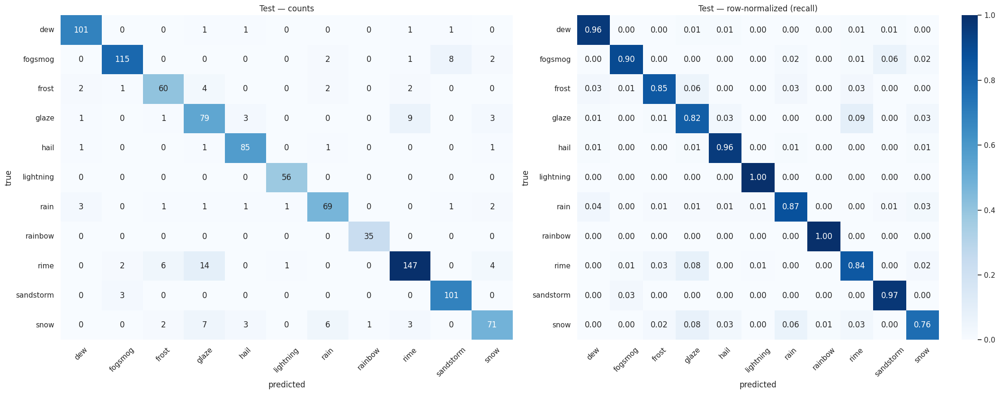

Top confusions (true -> predicted : rate):
       glaze -> rime      : 0.094
        rime -> glaze     : 0.080
        snow -> glaze     : 0.075
        snow -> rain      : 0.065
     fogsmog -> sandstorm : 0.062
       frost -> glaze     : 0.056
        rain -> dew       : 0.038
        rime -> frost     : 0.034


In [37]:
plot_confusion(test_targets, test_preds, "Test")

## 7.3 Prediction Grid

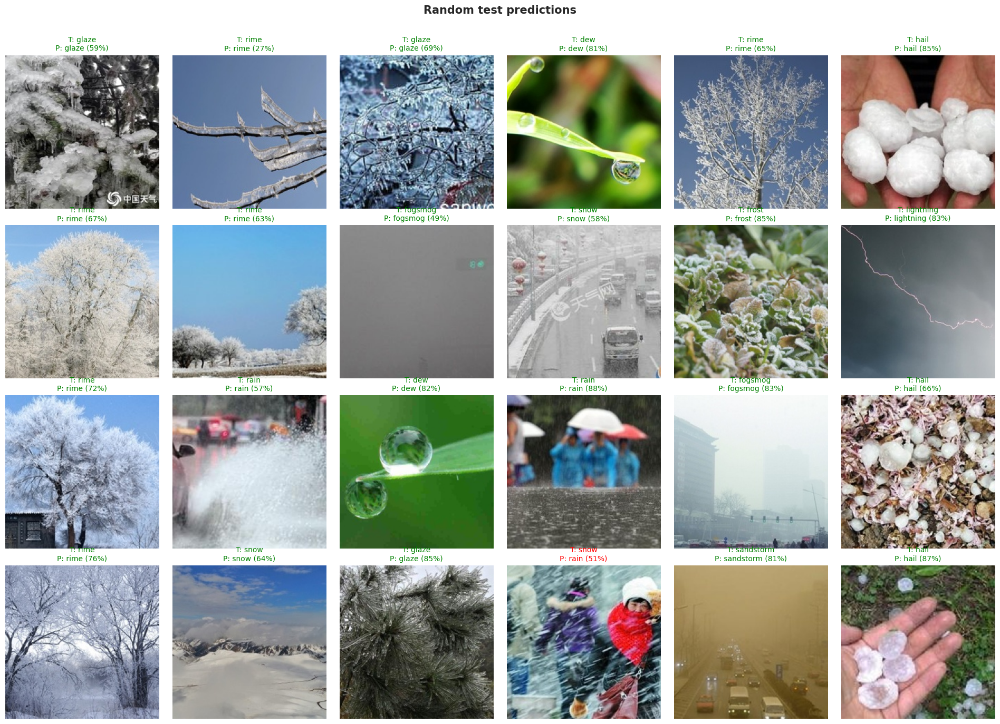

In [38]:
def plot_prediction_grid(frame, title, n_cols=6):
    n_rows = math.ceil(len(frame) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.5 * n_rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, row) in zip(np.ravel(axes), frame.iterrows()):
        ax.imshow(DISPLAY_TRANSFORM(get_image(row["path"])))
        color = "green" if row["correct"] else "red"
        ax.set_title(f"T: {row['label']}\nP: {row['pred']} ({row['confidence']:.0%})", color=color, fontsize=10)
    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


plot_prediction_grid(test_df.sample(min(CFG.N_PRED_SAMPLES, len(test_df)), random_state=CFG.SEED), "Random test predictions")

## 7.4 Most Confident Errors

Test errors: 111 / 1030


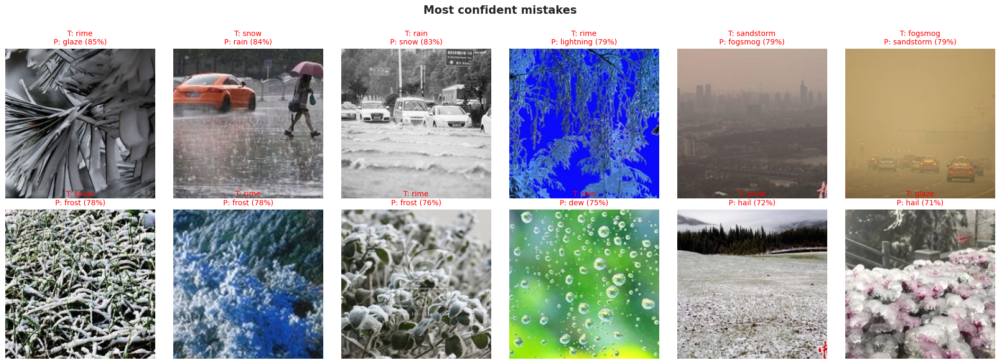

In [39]:
errors = test_df[~test_df["correct"]].sort_values("confidence", ascending=False)
print(f"Test errors: {len(errors)} / {len(test_df)}")
if len(errors):
    plot_prediction_grid(errors.head(CFG.N_ERROR_SAMPLES), "Most confident mistakes")

# 8. Test with URL Images

## 8.1 URL Helpers

In [40]:
def load_image_from_url(url, timeout=30):
    response = requests.get(url, headers={"User-Agent": CFG.URL_USER_AGENT}, timeout=timeout)
    response.raise_for_status()
    img = Image.open(BytesIO(response.content))
    img.draft("RGB", (CFG.CACHE_SHORT_SIDE, CFG.CACHE_SHORT_SIDE))
    return img.convert("RGB")


@torch.no_grad()
def predict_image(model, img, tta=CFG.TTA):
    model = unwrap(model).eval()
    x = build_transforms(train=False)(img).unsqueeze(0).to(DEVICE)
    probs = model(x).float().softmax(1)
    if tta:
        probs = (probs + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
    return probs[0].cpu().numpy()


def show_url_prediction(img, probs, url):
    top = np.argsort(probs)[::-1][:CFG.TOP_K]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
    axes[0].imshow(img)
    axes[0].axis("off")
    axes[0].set_title(f"{CFG.CLASSES[top[0]]} ({probs[top[0]]:.1%})", fontsize=13, fontweight="bold")
    axes[1].barh([CFG.CLASSES[i] for i in top][::-1], probs[top][::-1], color=sns.color_palette("viridis", CFG.TOP_K)[::-1])
    for i, v in enumerate(probs[top][::-1]):
        axes[1].text(v + 0.01, i, f"{v:.1%}", va="center")
    axes[1].set(xlim=(0, 1.15), title=f"Top-{CFG.TOP_K}")
    fig.suptitle(url.split("/")[-1][:90], fontsize=9, color="gray")
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

## 8.2 Predictions

Edit `CFG.URLS` (or the list below) with any image URLs.

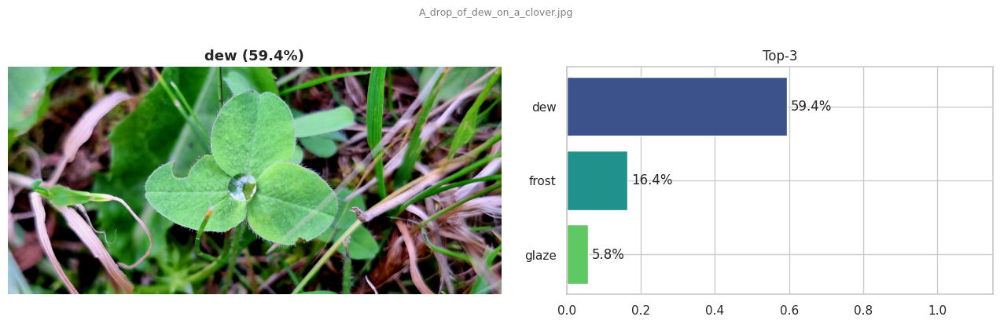

Could not load https://cms.accuweather.com/wp-content/uploads/2019/01/static-hoarfrost-germany-ap.jpg
  -> 403 Client Error: Forbidden for url: https://cms.accuweather.com/wp-content/uploads/2019/01/static-hoarfrost-germany-ap.jpg


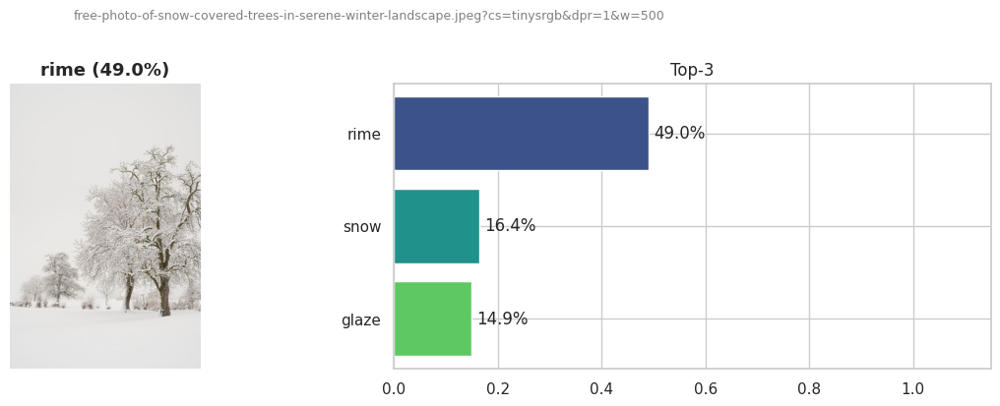

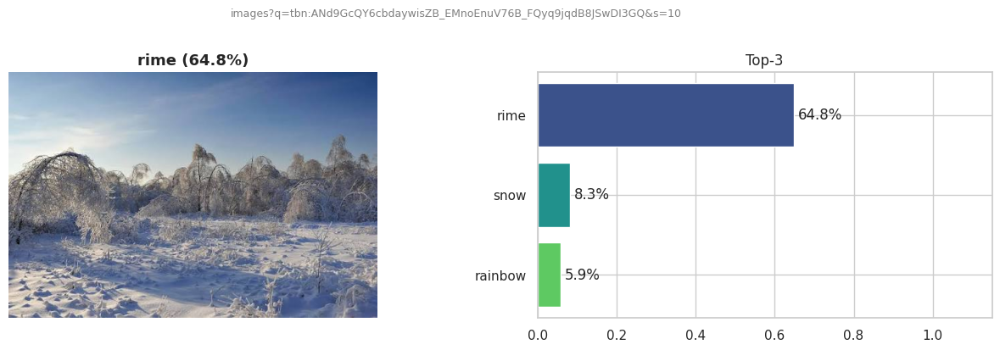

Could not load https://upload.wikimedia.org/wikipedia/commons/9/94/Granizo.jpg
  -> 429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/9/94/Granizo.jpg
Could not load https://upload.wikimedia.org/wikipedia/commons/c/c2/Port_and_lighthouse_overnight_storm_with_lightning_in_Port-la-Nouvelle.jpg
  -> 429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/c/c2/Port_and_lighthouse_overnight_storm_with_lightning_in_Port-la-Nouvelle.jpg
Could not load https://upload.wikimedia.org/wikipedia/commons/6/65/Hard_rain_on_a_roof.jpg
  -> 429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/6/65/Hard_rain_on_a_roof.jpg


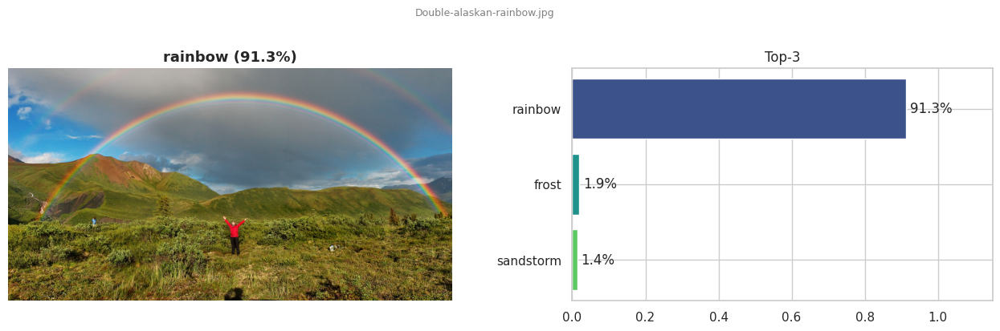

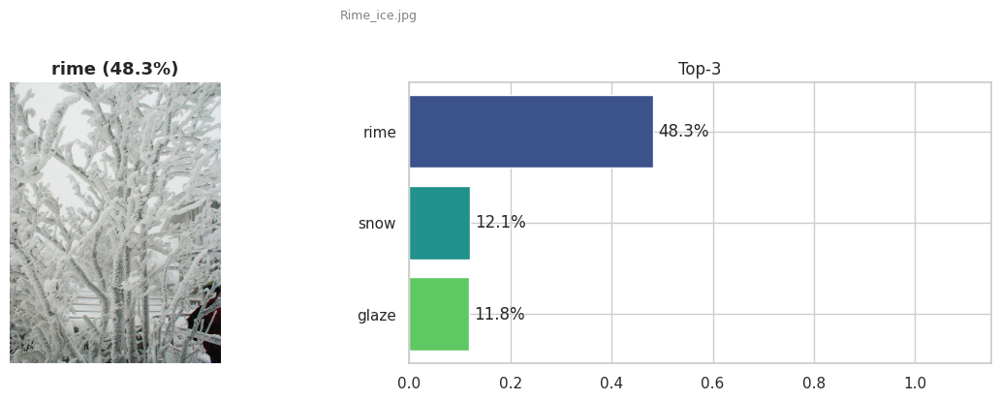

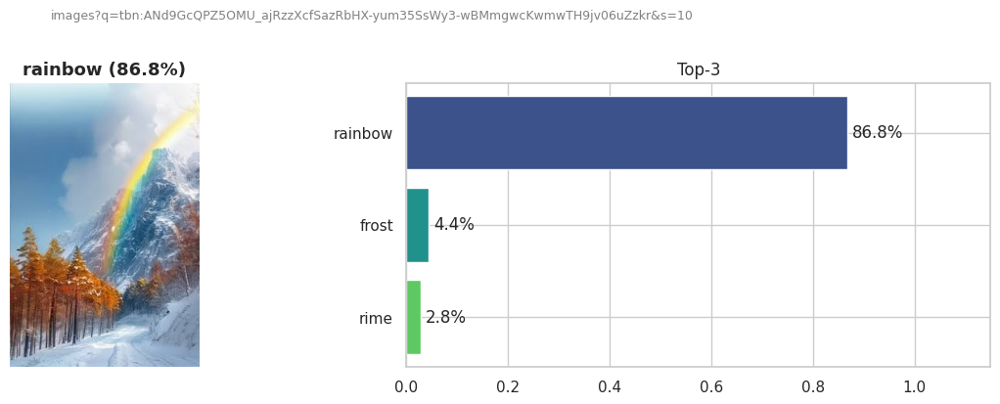

Could not load https://upload.wikimedia.org/wikipedia/commons/1/12/CargoNet_Di_12_Euro_4000_L%C3%B8nsdal_-_Bolna.jpg
  -> 429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/1/12/CargoNet_Di_12_Euro_4000_L%C3%B8nsdal_-_Bolna.jpg


,url,prediction,confidence
0,A_drop_of_dew_on_a_clover.jpg,dew,0.594
1,free-photo-of-snow-covered-trees-in-serene-win...,rime,0.490
2,images?q=tbn:ANd9GcQY6cbdaywisZB_EMnoEnuV76B_F...,rime,0.648
3,Double-alaskan-rainbow.jpg,rainbow,0.913
4,Rime_ice.jpg,rime,0.483
5,images?q=tbn:ANd9GcQPZ5OMU_ajRzzXcfSazRbHX-yum...,rainbow,0.868


In [49]:
URLS = CFG.URLS

url_rows = []
for url in URLS:
    try:
        img = load_image_from_url(url)
    except Exception as e:
        print(f"Could not load {url}\n  -> {e}")
        continue
    probs = predict_image(infer_model, img)
    show_url_prediction(img, probs, url)
    url_rows.append({"url": url.split("/")[-1][:60], "prediction": CFG.CLASSES[probs.argmax()], "confidence": probs.max()})

if url_rows:
    display(pd.DataFrame(url_rows).round(3))